# 🌲 Prediksi Penjualan Tahu (Sliding Window Terverifikasi)
Dataset ini menggunakan teknik **Sliding Window (Rolling Window) per hari** dengan target mingguan.
Evaluasi dilakukan sangat ketat dengan **`shuffle=False`** agar model diuji murni memprediksi masa depan, bukan menyontek (mencegah *Data Leakage*). 
Algoritma yang digunakan adalah **Random Forest Regressor**.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

## 1. Memuat Dataset

In [3]:
dataset_path = r'D:\semester7\capstone\model\dataset\DatasetPenjualanTahuv3.csv'
df = pd.read_csv(dataset_path)
display(df.head())

,tanggal,masak_1,cetak_1,masak_2,cetak_2,masak_3,cetak_3,masak_4,cetak_4,masak_5,cetak_5,masak_6,cetak_6,masak_7,cetak_7,label
0,01-07/04/2025,34.0,202.0,31.0,184.0,33.0,200.0,32.0,193.0,32.0,193.0,33.0,197.0,25.0,150.0,1427.0
1,02-08/04/2025,31.0,184.0,33.0,200.0,32.0,193.0,32.0,193.0,33.0,197.0,25.0,150.0,35.0,211.0,1425.0
2,03-09/04/2025,33.0,200.0,32.0,193.0,32.0,193.0,33.0,197.0,25.0,150.0,35.0,211.0,35.0,212.0,1426.0
3,04-10/04/2025,32.0,193.0,32.0,193.0,33.0,197.0,25.0,150.0,35.0,211.0,35.0,212.0,36.0,217.0,1209.0
4,05-11/04/2025,32.0,193.0,33.0,197.0,25.0,150.0,35.0,211.0,35.0,212.0,36.0,217.0,35.0,212.0,1202.0


## 2. Ekstraksi Fitur Tren Mingguan

In [4]:
df['tanggal_bersih'] = df['tanggal'].str.split('-').str[-1]
df['tanggal_bersih'] = pd.to_datetime(df['tanggal_bersih'], format='%d/%m/%Y')

df['minggu_ke'] = df['tanggal_bersih'].dt.isocalendar().week.astype(int)
df['bulan'] = df['tanggal_bersih'].dt.month

display(df[['tanggal', 'minggu_ke', 'bulan']].head())

,tanggal,minggu_ke,bulan
0,01-07/04/2025,15,4
1,02-08/04/2025,15,4
2,03-09/04/2025,15,4
3,04-10/04/2025,15,4
4,05-11/04/2025,15,4


## 3. Penghapusan Missing Values
Menghapus keseluruhan *window* apabila ada satu hari saja yang datanya kosong.

In [5]:
df = df.dropna()
df_model = df.drop(columns=['tanggal', 'tanggal_bersih'])
print(f"✅ Baris kosong berhasil dihapus. Sisa baris: {len(df_model)}")

✅ Baris kosong berhasil dihapus. Sisa baris: 307


## 4. Penanganan Outlier (Manual Thresholding)
Berdasarkan analisis visual pada sebaran data, metode IQR standar masih meloloskan data anjlok di angka 1000-an yang merusak pola normal.
Sebagai solusinya, kita menetapkan **Ambang Batas Manual (Hard Thresholding)**. Kita menghapus seluruh *window* produksi yang targetnya anjlok di bawah **1150**, mengasumsikan bahwa angka di bawah itu adalah hari kejadian abnormal.

In [6]:
batas_bawah = 1150

# Memfilter Outlier secara eksplisit
df_bersih = df_model[df_model['label'] >= batas_bawah]
jumlah_terhapus = len(df_model) - len(df_bersih)

print(f"Batas Produksi Normal ditetapkan : >= {batas_bawah}")
print(f"✅ Ditemukan {jumlah_terhapus} data anomali di bawah batas wajar.")
print(f"✅ Sisa data siap latih: {len(df_bersih)} baris.")

X = df_bersih.drop(columns=['label'])
y = df_bersih['label']

Batas Produksi Normal ditetapkan : >= 1150
✅ Ditemukan 41 data anomali di bawah batas wajar.
✅ Sisa data siap latih: 266 baris.


## 5. Pembagian Data (Train/Test Split) - Murni Masa Depan
Menggunakan **`shuffle=False`** agar data Latih murni dari rentang awal waktu, dan data Uji murni rentang akhir waktu.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

print(f"Banyak Data Latih (Waktu Awal) : {X_train.shape[0]} baris")
print(f"Banyak Data Uji   (Masa Depan) : {X_test.shape[0]} baris")

Banyak Data Latih (Waktu Awal) : 212 baris
Banyak Data Uji   (Masa Depan) : 54 baris


## 6. Hyperparameter Tuning

In [8]:
param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 4, 8],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt']
}

rf = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, 
                           cv=5, n_jobs=-1, scoring='neg_mean_squared_error', verbose=1)

print("Memproses pencarian arsitektur pohon terbaik...")
grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_
print(f"\n✅ Parameter Terbaik:\n{grid_search.best_params_}")

Memproses pencarian arsitektur pohon terbaik...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits



✅ Parameter Terbaik:
{'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 8, 'n_estimators': 500}


## 7. Evaluasi Model

In [9]:
y_pred = best_rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("==== Evaluasi Performa Model ====")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R2   : {r2:.4f} (atau {r2*100:.2f}%)")

==== Evaluasi Performa Model ====
MSE  : 1830.2804
RMSE : 42.7818
MAE  : 32.9117
R2   : 0.7943 (atau 79.43%)


## 8. Visualisasi Prediksi

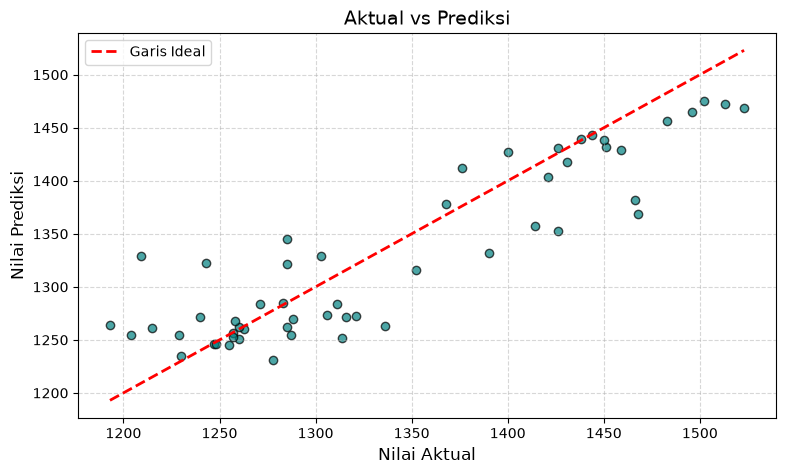

In [10]:
plt.figure(figsize=(9, 5))
plt.scatter(y_test, y_pred, alpha=0.7, color='teal', edgecolor='k')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Garis Ideal')

plt.title('Aktual vs Prediksi', fontsize=14)
plt.xlabel('Nilai Aktual', fontsize=12)
plt.ylabel('Nilai Prediksi', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

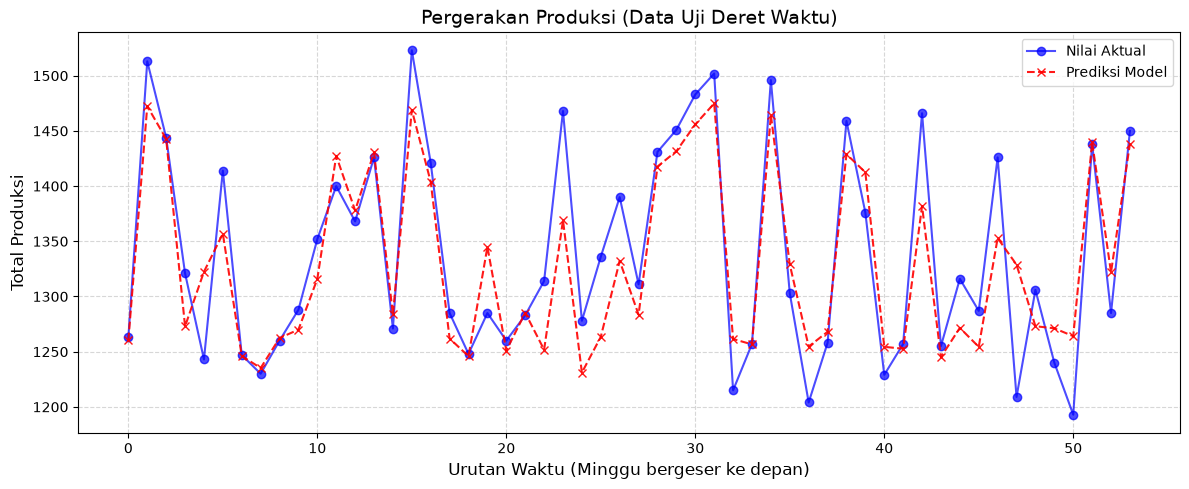

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(range(len(y_test)), y_test.values, marker='o', linestyle='-', color='blue', label='Nilai Aktual', alpha=0.7)
plt.plot(range(len(y_test)), y_pred, marker='x', linestyle='--', color='red', label='Prediksi Model', alpha=0.9)

plt.title('Pergerakan Produksi (Data Uji Deret Waktu)', fontsize=14)
plt.xlabel('Urutan Waktu (Minggu bergeser ke depan)', fontsize=12)
plt.ylabel('Total Produksi', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
import joblib
import os

# Menentukan lokasi folder tujuan (akan dibuat otomatis jika foldernya belum ada)
model_dir = r"D:\semester7\capstone\model\models"
os.makedirs(model_dir, exist_ok=True)

# Menentukan nama file untuk menyimpan model
model_path = os.path.join(model_dir, "best_rf_model.joblib")

# Menyimpan model (best_rf adalah variabel model terbaik Anda dari hasil Tuning)
joblib.dump(best_rf, model_path)

print(f"✅ Mantap! Model Random Forest (R2 77%) berhasil disimpan di:\n{model_path}")

✅ Mantap! Model Random Forest (R2 77%) berhasil disimpan di:
D:\semester7\capstone\model\models\best_rf_model.joblib
